Billy York

07/29/26

# Evaluating the Model on Live Data

## Introduction

This milestone is where the previous few milestones tie together. It's an adaptation of the batch cleaning job, but this time sending each event to the prediction service to evaluate the model.

## Analysis

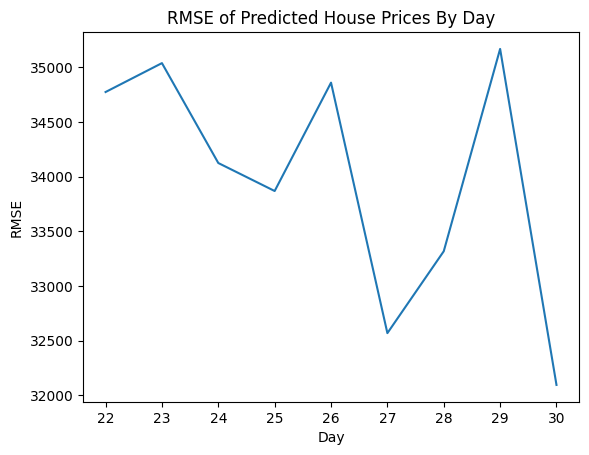

The Root-Mean-Squared-Error Plot shows the model is likely experiencing some form of data drift. This is likely the economic conditions factor being introduced. It seems to cycle every three or so days, but each day is significantly higher than the training validation was, a little more than 32,000 now versus the 28260 from the training validation, meaning the +/- for the predicted price is about 4,000 higher.

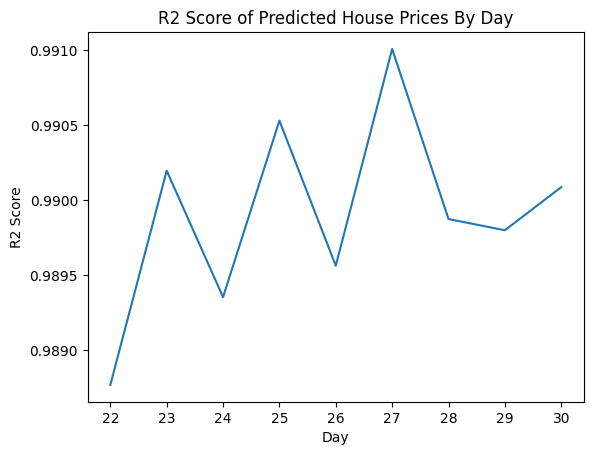

The R2 Score Plot shows a near inverse of the RMSE, again suggesting the data drift depending on the day. This one shows a more clear stair step of the data, though it appears to improve the longer the simulator is running. This could be due to having to retrain the model a few times while building the prediction service for various reasons like improper imports and python version differences. Economic Conditions were accounted for by limiting the feature to just records with it set to 1.0. That being said, the R2 score is still lower than it was during the initial training validation by about 0.002. 

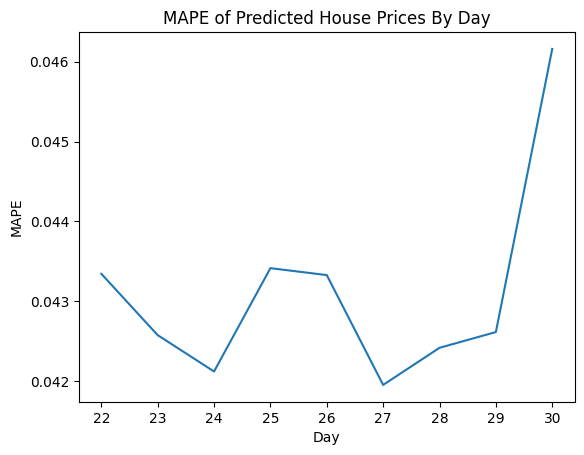

The Mean Average Percentage Error Plot is an interesting plot when compared to the RMSE and R2 Scores. In the original training validation, the shape of the MAPE and the RMSE were nearly identical, where as in this evaluation the MAPE shows a completely different plot. There is even an instance of the direction between days changing, specifically between days 25 and 26. The RMSE goes up fairly sharply, but the MAPE goes down slightly. This is likely from a few significant outliers being present on day 26 which would throw off the RMSE much more than the MAPE.

## Appendix: The Evaluation Job Running

### Running containers

![milestone5.png](milestone5.png)

### Table schemas

![milestone5_5.png](milestone5_5.png)

![milestone5_6.png](milestone5_6.png)

### Sample records

![milestone5_3.png](milestone5_3.png)

![milestone5_4.png](milestone5_4.png)

In [ ]:
import pandas as pd
import psycopg
import seaborn as sns
from psycopg.rows import dict_row
from sklearn.metrics import (
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)


In [10]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [11]:
conn_string = 'postgresql://{}:{}@{}:5432/house_price_prediction_service'.format(user, password, host)
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT id, sale_date, true_price, predicted_price FROM evaluated_home_sale_events;')
        # rows will be a list of dicts with the keys 'id', 'event_timestamp', and 'data'
        rows = cur.fetchall()

In [12]:
df = pd.DataFrame.from_records(rows)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25608 entries, 0 to 25607
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id               25608 non-null  int64         
 1   sale_date        25608 non-null  datetime64[us]
 2   true_price       25608 non-null  object        
 3   predicted_price  25608 non-null  object        
dtypes: datetime64[us](1), int64(1), object(2)
memory usage: 800.4+ KB


In [13]:
grouped = df.groupby(by=df['sale_date'].dt.day)
records = []
for group in grouped:
    rmse = root_mean_squared_error(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
    r2 = r2_score(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
    mape = mean_absolute_percentage_error(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
    record = {'day': group[0], 'rmse': rmse, 'r2': r2, 'mape': mape}
    records.append(record)
stats = pd.DataFrame.from_records(records)
stats.head()

,day,rmse,r2,mape
0,21,34129.185138,0.990687,0.043122
1,22,33933.390952,0.989042,0.043253
2,23,35039.479145,0.990196,0.042574
3,24,34124.949722,0.989355,0.042119
4,25,33868.649104,0.990529,0.043413


[Text(0.5, 1.0, 'RMSE of Predicted House Prices By Day'),
 Text(0.5, 0, 'Day'),
 Text(0, 0.5, 'RMSE')]

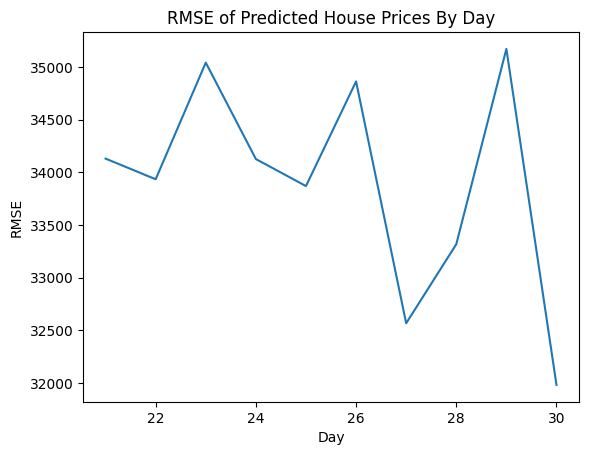

In [14]:
sns.lineplot(x=stats['day'], y=stats['rmse']).set(title='RMSE of Predicted House Prices By Day', xlabel='Day', ylabel='RMSE')

[Text(0.5, 1.0, 'R2 Score of Predicted House Prices By Day'),
 Text(0.5, 0, 'Day'),
 Text(0, 0.5, 'R2 Score')]

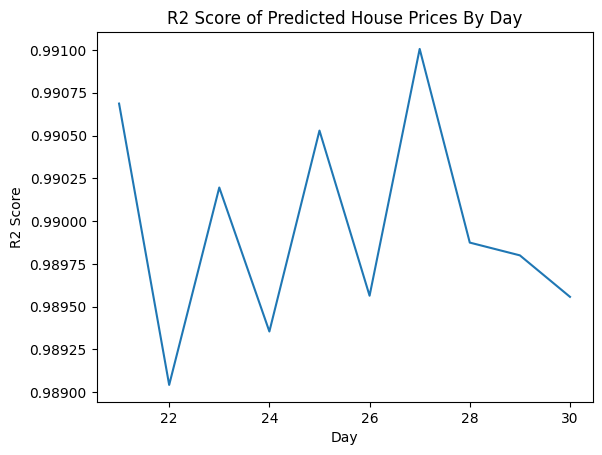

In [15]:
sns.lineplot(x=stats['day'], y=stats['r2']).set(title='R2 Score of Predicted House Prices By Day', xlabel='Day', ylabel='R2 Score')

[Text(0.5, 1.0, 'MAPE of Predicted House Prices By Day'),
 Text(0.5, 0, 'Day'),
 Text(0, 0.5, 'MAPE')]

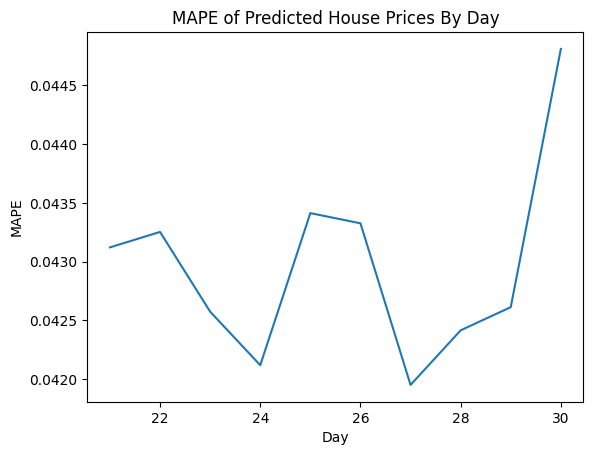

In [16]:
sns.lineplot(x=stats['day'], y=stats['mape']).set(title='MAPE of Predicted House Prices By Day', xlabel='Day', ylabel='MAPE')